In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df = pd.read_csv('../data/bank-full.csv', sep=';')

df = df.drop(columns=['duration'])
target = 'y'
positive_class = 1

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,no


In [17]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()
date_cols = df.select_dtypes(include="datetime").columns.tolist()

print(f"num cols: {num_cols}")
print(f"cat cols: {cat_cols}")
print(f"date cols: {date_cols}")

num cols: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
cat cols: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']
date cols: []


In [18]:
df.loc[:, cat_cols].describe()

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [19]:
df.describe()

,age,balance,day,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,63.000000,871.000000,275.000000


In [20]:
num = df[num_cols].replace([np.inf, -np.inf], np.nan)

stats = num.describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T

Q1 = num.quantile(0.25)
Q3 = num.quantile(0.75)
IQR = Q3 - Q1

stats["skew"] = num.skew()
stats["missing_%"] = num.isna().mean() * 100
stats["zeros_%"] = num.eq(0).mean() * 100
stats["negative_%"] = num.lt(0).mean() * 100

stats["outliers_%"] = (
    num.lt(Q1 - 1.5 * IQR) |
    num.gt(Q3 + 1.5 * IQR)
).mean() * 100

display(stats.round(2))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,missing_%,zeros_%,negative_%,outliers_%
age,45211.0,40.94,10.62,18.0,23.0,27.0,33.0,39.0,48.0,59.0,71.0,95.0,0.68,0.0,0.00,0.00,1.08
balance,45211.0,1362.27,3044.77,-8019.0,-627.0,-172.0,72.0,448.0,1428.0,5768.0,13164.9,102127.0,8.36,0.0,7.77,8.33,10.46
day,45211.0,15.81,8.32,1.0,2.0,3.0,8.0,16.0,21.0,29.0,31.0,31.0,0.09,0.0,0.00,0.00,0.00
campaign,45211.0,2.76,3.10,1.0,1.0,1.0,1.0,2.0,3.0,8.0,16.0,63.0,4.90,0.0,0.00,0.00,6.78
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,317.0,370.0,871.0,2.62,0.0,0.00,81.74,18.26
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,0.0,0.0,3.0,8.9,275.0,41.85,0.0,81.74,0.00,18.26


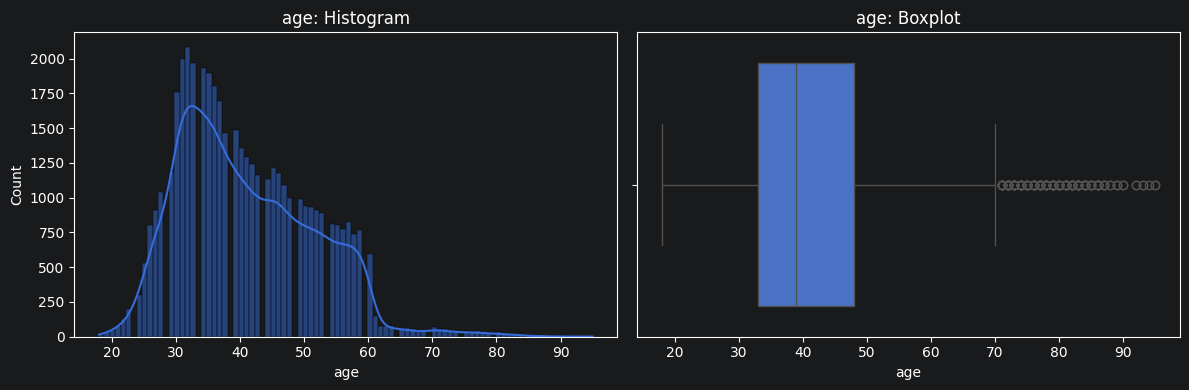

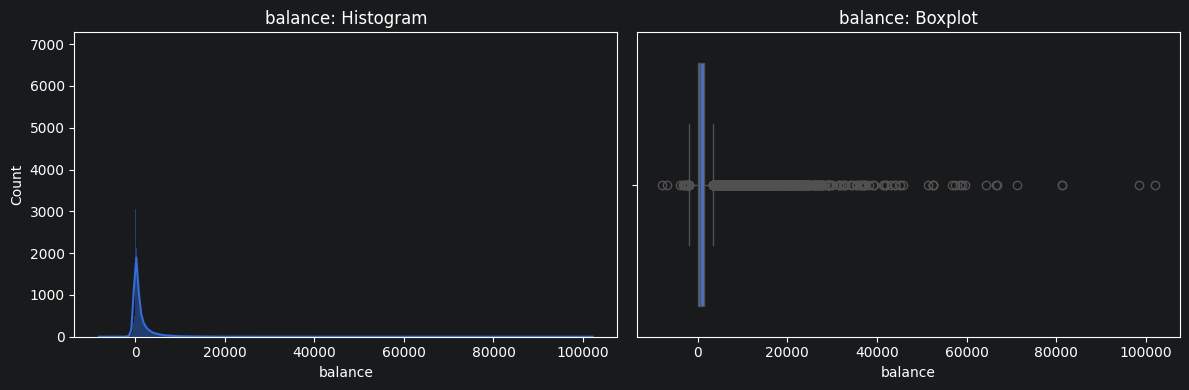

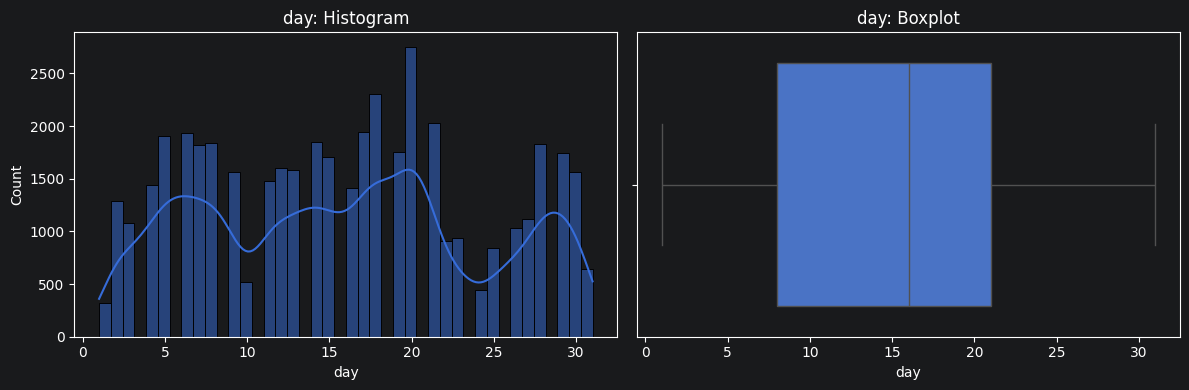

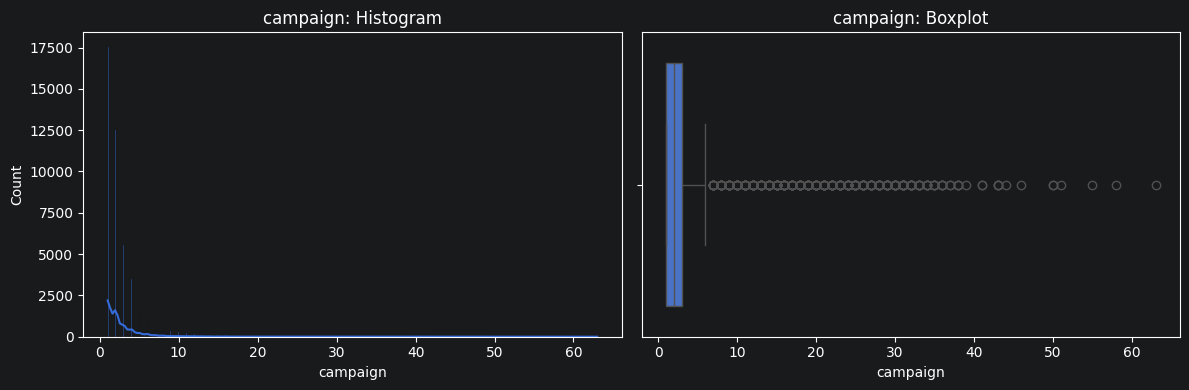

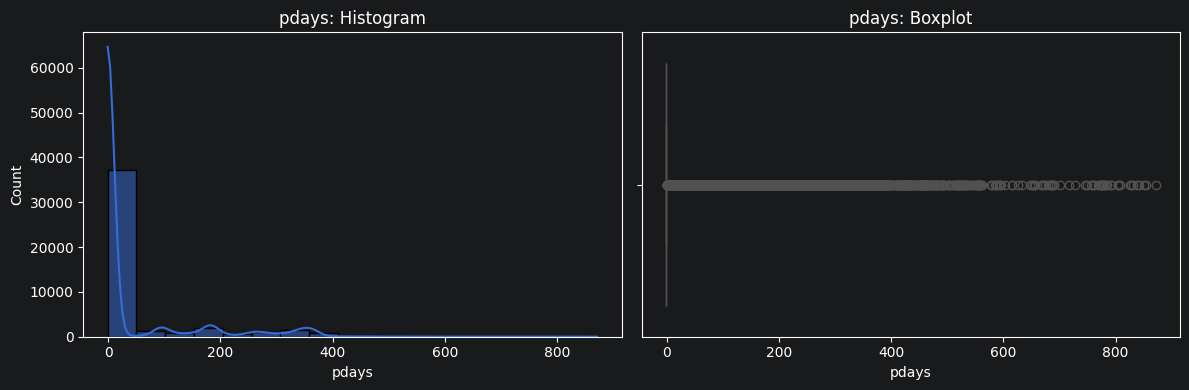

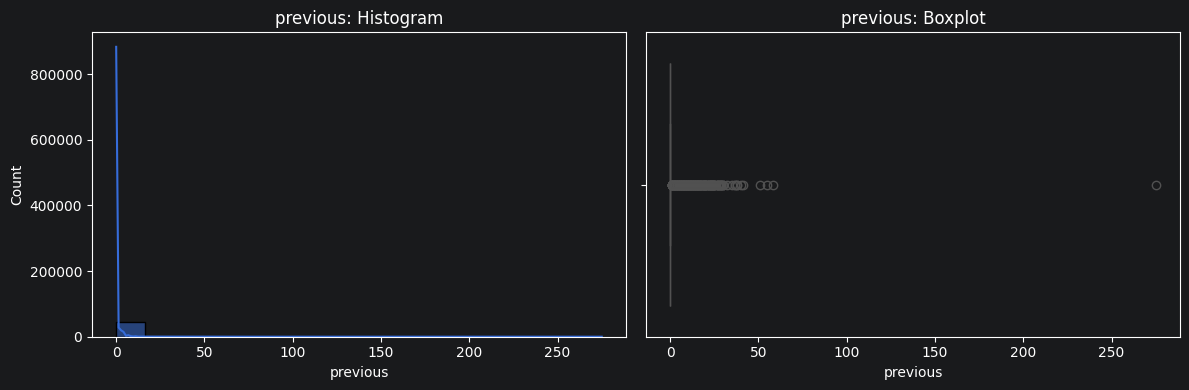

In [21]:
for col in num_cols:
    data = num[col].dropna()

    if data.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(data, kde=True, ax=axes[0])
    axes[0].set_title(f"{col}: Histogram")

    sns.boxplot(x=data, ax=axes[1])
    axes[1].set_title(f"{col}: Boxplot")

    plt.tight_layout()
    plt.show()

In [22]:
cat_stats = pd.DataFrame(index=cat_cols)

cat_stats["unique"] = df[cat_cols].nunique()
cat_stats["missing_%"] = df[cat_cols].isna().mean() * 100

cat_stats["unique_ratio_%"] = (
    cat_stats["unique"] / len(df) * 100
)

cat_stats["rare_categories"] = [
    (df[col].value_counts(normalize=True) < 0.01).sum()
    for col in cat_cols
]

cat_stats["most_frequent_%"] = [
    df[col].value_counts(normalize=True).iloc[0] * 100
    if df[col].notna().any() else np.nan
    for col in cat_cols
]

display(cat_stats.round(2))

,unique,missing_%,unique_ratio_%,rare_categories,most_frequent_%
job,12,0.0,0.03,1,21.53
marital,3,0.0,0.01,0,60.19
education,4,0.0,0.01,0,51.32
default,2,0.0,0.00,0,98.20
housing,2,0.0,0.00,0,55.58
loan,2,0.0,0.00,0,83.98
contact,3,0.0,0.01,0,64.77
month,12,0.0,0.03,1,30.45
poutcome,4,0.0,0.01,0,81.75
y,2,0.0,0.00,0,88.30


In [23]:
quality = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
    "unique": df.nunique(),
    "unique_%": df.nunique() / len(df) * 100
})

display(quality.sort_values("missing_%", ascending=False).round(2))

print("dataset size:", df.shape)
print("amount of duplicates:", df.duplicated().sum())
print("duplicates ratio:", round(df.duplicated().mean() * 100, 2), "%")

,dtype,missing,missing_%,unique,unique_%
age,int64,0,0.0,77,0.17
job,object,0,0.0,12,0.03
marital,object,0,0.0,3,0.01
education,object,0,0.0,4,0.01
default,object,0,0.0,2,0.00
balance,int64,0,0.0,7168,15.85
housing,object,0,0.0,2,0.00
loan,object,0,0.0,2,0.00
contact,object,0,0.0,3,0.01
day,int64,0,0.0,31,0.07


dataset size: (45211, 16)
amount of duplicates: 16
duplicates ratio: 0.04 %


,count,percentage
y,,
no,39922,88.3
yes,5289,11.7


Missing targets: 0
Number of classes: 2


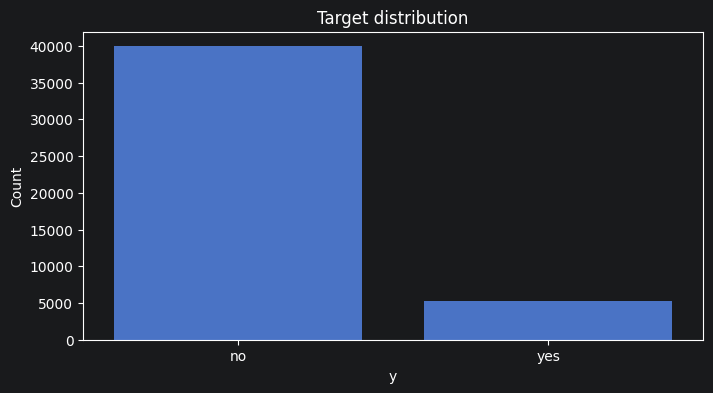

In [24]:
y = df[target]

class_counts = y.value_counts(dropna=False)
class_perc = y.value_counts(normalize=True, dropna=False) * 100

class_stats = pd.DataFrame({
    "count": class_counts,
    "percentage": class_perc
})

display(class_stats.round(2))

print("Missing targets:", y.isna().sum())
print("Number of classes:", y.nunique())

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x=target, order=y.value_counts().index)
plt.title("Target distribution")
plt.ylabel("Count")
plt.show()

In [25]:
valid_y = y.dropna()
counts = valid_y.value_counts()

print("Minimum class count:", counts.min())
print("Maximum class count:", counts.max())

print("Minority class share:", round(
    counts.min() / len(valid_y) * 100, 2
), "%")

print("Majority baseline accuracy:", round(
    counts.max() / len(valid_y) * 100, 2
), "%")

Minimum class count: 5289
Maximum class count: 39922
Minority class share: 11.7 %
Majority baseline accuracy: 88.3 %


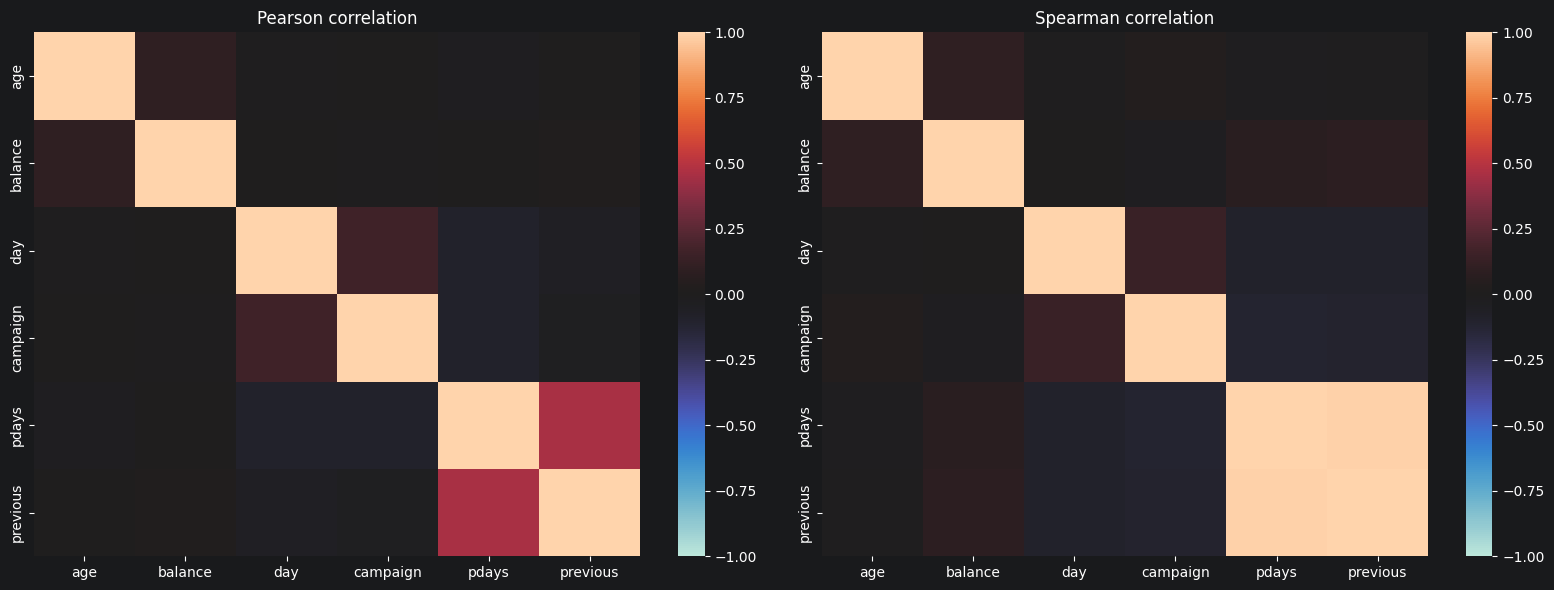

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pearson = df[num_cols].corr(method="pearson")
spearman = df[num_cols].corr(method="spearman")

sns.heatmap(
    pearson, center=0,
    vmin=-1, vmax=1, ax=axes[0]
)
axes[0].set_title("Pearson correlation")

sns.heatmap(
    spearman, center=0,
    vmin=-1, vmax=1, ax=axes[1]
)
axes[1].set_title("Spearman correlation")

plt.tight_layout()
plt.show()

In [27]:
corr = df[num_cols].corr().abs()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = upper.stack()
high_corr = high_corr[high_corr > 0.9]

display(
    high_corr.sort_values(ascending=False)
    .rename("correlation")
    .to_frame()
)

,,correlation


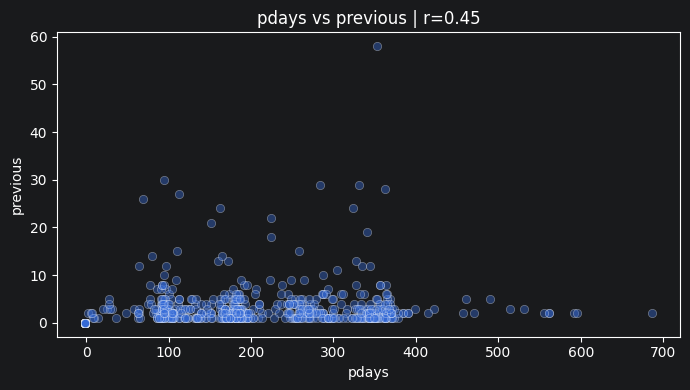

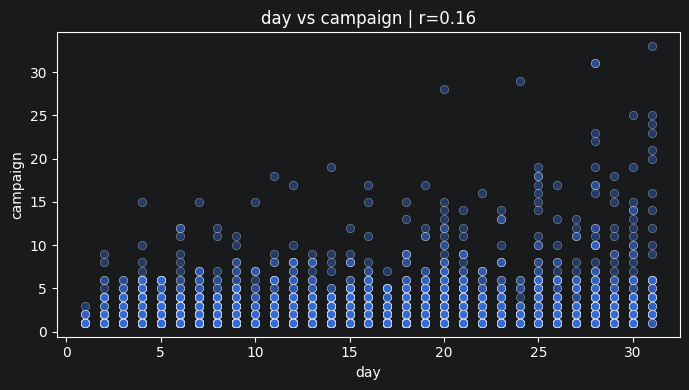

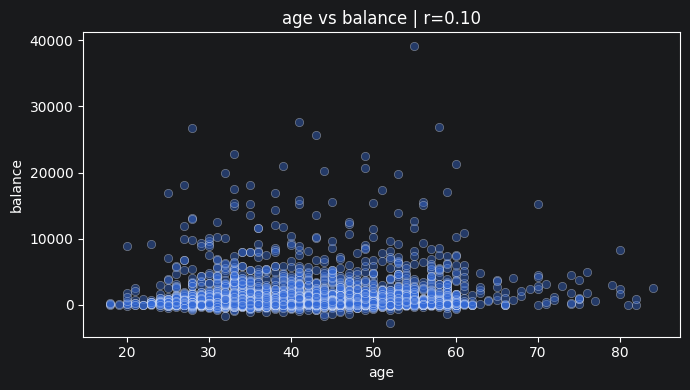

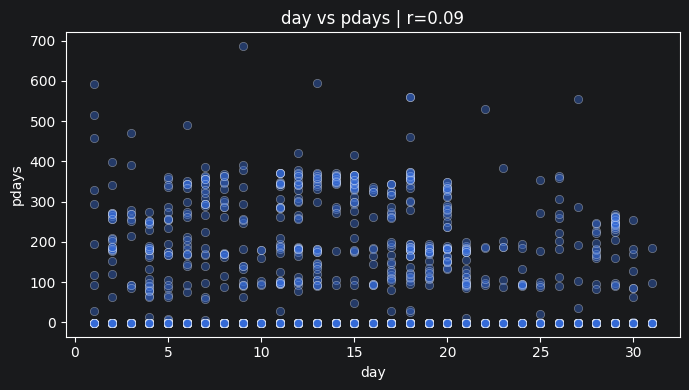

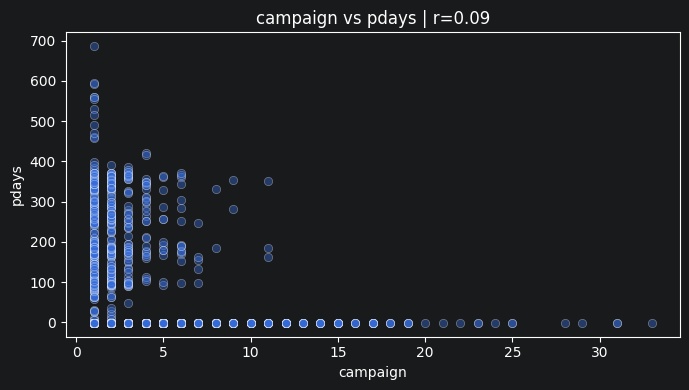

In [28]:
pairs = (
    upper.stack()
    .sort_values(ascending=False)
    .head(5)
)

sample = df.sample(
    n=min(3000, len(df)),
    random_state=42
)

for (col1, col2), corr_value in pairs.items():
    plt.figure(figsize=(7, 4))

    sns.scatterplot(
        data=sample,
        x=col1,
        y=col2,
        alpha=0.4
    )

    plt.title(f"{col1} vs {col2} | r={corr_value:.2f}")
    plt.tight_layout()
    plt.show()

### Thoughts:
- Majority baseline accuracy: 88.3 % - target disbalance.
- column 'duration' removed
